# 05 – Checking our results against Global Forest Watch

In notebook 04 the model said: *"these patches lost forest between 2019 and 2025."* But that's just the model's word. To trust it, we compare with an **independent** source.

**Global Forest Watch (GFW)** publishes yearly **tree cover loss** maps for the whole planet. They come from the **Hansen / University of Maryland** dataset (first published in the journal *Science* in 2013, updated every year):
- made from **Landsat** satellite images at **30 m** per pixel (our Sentinel-2 images are 10 m)
- each pixel says *in which year* its trees were removed, or 0 if never
- built by a completely different team, method and satellite, which is what makes it a fair check

**In this notebook:**
1. Download GFW's loss data for our exact 16 km area and line it up with our patch grid
2. See *when* the forest was lost, year by year
3. Score our detections: what we got right, false alarms, and misses
4. Try an improved detection method and see if it beats the simple one
5. Summarise the numbers for the paper

Takes about a minute. **Run → Run All Cells**, then read along.

## Step 1 – Setup and load our results from notebook 04

`hasdeo_predictions.npz` holds everything notebook 04 saved: each patch's predicted class and confidence for both years, all 10 probabilities, and **where on Earth** the grid sits (`crs` + `transform`).

`transform` is the recipe for turning a pixel position into map coordinates: where the top-left corner is, and that each pixel is 10 m.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from matplotlib.colors import ListedColormap

import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.windows import from_bounds
from affine import Affine
from pystac_client import Client

FIG_DIR = Path("../figures")
RESULTS = np.load("../results/hasdeo_predictions.npz")

class_names = list(RESULTS["class_names"])
FOREST = class_names.index("Forest")
N_PATCHES, PATCH = 25, 64
SIZE = N_PATCHES * PATCH
PATCH_KM2 = 0.4096
grid_transform = Affine(*RESULTS["transform"])
grid_crs = str(RESULTS["crs"])

pred_2019, pred_2025 = RESULTS["pred_2019"], RESULTS["pred_2025"]
forest_prob_2019 = RESULTS["probs_2019"][:, FOREST].reshape(N_PATCHES, N_PATCHES)
forest_prob_2025 = RESULTS["probs_2025"][:, FOREST].reshape(N_PATCHES, N_PATCHES)

our_loss = (pred_2019 == FOREST) & (pred_2025 != FOREST)     # notebook 04's detections
print("Our detected forest-loss patches:", our_loss.sum())
print("Grid:", grid_crs, "| top-left corner (m):", (grid_transform.c, grid_transform.f), "| pixel size:", grid_transform.a, "m")

Our detected forest-loss patches: 19
Grid: EPSG:32644 | top-left corner (m): (678140.0, 2534740.0) | pixel size: 10.0 m


We also re-download the 2025 satellite image for the same square, just to draw maps on top of. Same as notebook 04, but this time we cut it using the saved map coordinates.

In [2]:
left, top = grid_transform.c, grid_transform.f
right, bottom = left + SIZE * 10, top - SIZE * 10

catalog = Client.open("https://earth-search.aws.element84.com/v1")
item = catalog.get_collection("sentinel-2-l2a").get_item(str(RESULTS["scenes"][1]))
with rasterio.open(item.assets["visual"].href) as src:
    image_2025 = np.moveaxis(src.read(window=from_bounds(left, bottom, right, top, src.transform)), 0, -1)
print("2025 image:", image_2025.shape)

2025 image: (1600, 1600, 3)


## Step 2 – Download Global Forest Watch's loss data

GFW's data comes in 10° × 10° tiles. Ours is called `30N_080E` (its top-left corner is 30° N, 80° E). We need the **lossyear** layer of the latest version (**v1.13**, covering 2001–2025). Each pixel holds:
- `0` → no tree loss
- `1` … `25` → trees lost in 2001 … 2025 (so `19` = 2019, `24` = 2024)

**Lining the two up.** GFW uses latitude/longitude with ~30 m pixels; our grid uses UTM metres with 10 m pixels. `reproject` re-draws GFW's map onto *our* grid, so that `gfw_year[row, col]` is GFW's answer for exactly the same 10 m spot as our image pixel `[row, col]`. `Resampling.nearest` means each of our pixels just copies the closest GFW pixel. Averaging years would make no sense: "2019.5" isn't a year.

In [3]:
GFW_URL = "https://storage.googleapis.com/earthenginepartners-hansen/GFC-2025-v1.13/Hansen_GFC-2025-v1.13_lossyear_30N_080E.tif"

gfw_year = np.zeros((SIZE, SIZE), dtype=np.uint8)
with rasterio.open(GFW_URL) as src:
    print("GFW tile:", src.width, "x", src.height, "pixels |", src.crs, "| pixel size ≈", round(src.res[0] * 111_000), "m")
    reproject(rasterio.band(src, 1), gfw_year,
              dst_transform=grid_transform, dst_crs=grid_crs, resampling=Resampling.nearest)

print("Lined up with our grid:", gfw_year.shape)

GFW tile: 40000 x 40000 pixels | EPSG:4326 | pixel size ≈ 28 m
Lined up with our grid: (1600, 1600)


## Step 3 – When was the forest lost?

Count the loss pixels for each year (each of our pixels = 10 m × 10 m = 100 m², so 10,000 pixels = 1 km²).

**Which years count?** Our images are from **February 2019** and **February 2025**. So loss during 2019–2024 happened between our two images. Loss marked **2025** mostly happened *after* our 2025 image was taken, so we can't expect our model to see it. It's shown in grey.

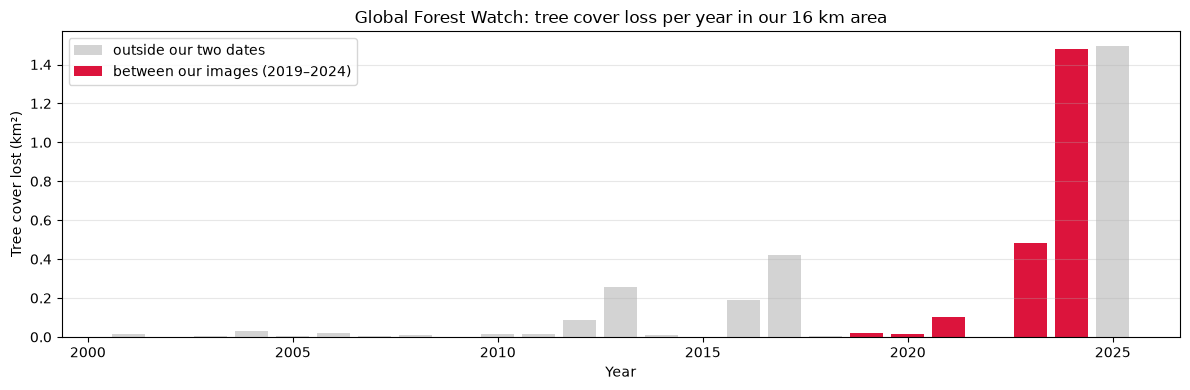

  2017:  0.42 km²
  2018:  0.01 km²
  2019:  0.02 km²
  2020:  0.01 km²
  2021:  0.10 km²
  2022:  0.00 km²
  2023:  0.48 km²
  2024:  1.48 km²
  2025:  1.50 km²
Total 2019–2024: 2.09 km²


In [4]:
years = np.arange(2001, 2026)
km2 = np.array([(gfw_year == y - 2000).sum() for y in years]) / 10_000
in_window = (years >= 2019) & (years <= 2024)

plt.figure(figsize=(12, 4))
plt.bar(years[~in_window], km2[~in_window], color="lightgray", label="outside our two dates")
plt.bar(years[in_window], km2[in_window], color="crimson", label="between our images (2019–2024)")
plt.xlabel("Year"); plt.ylabel("Tree cover lost (km²)")
plt.title("Global Forest Watch: tree cover loss per year in our 16 km area")
plt.legend(); plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "gfw_loss_per_year.png", dpi=150)
plt.show()

for y, a in zip(years, km2):
    if y >= 2017:
        print(f"  {y}: {a:5.2f} km²")
print(f"Total 2019–2024: {km2[in_window].sum():.2f} km²")

Clearing speeds up sharply in **2023–2025**, consistent with news reports of tree felling for the mine expansion in those years. And the biggest year, 2025, is still going on *after* our second image. A follow-up study with a 2026 image would catch it.

### Where was it lost?

GFW's loss pixels drawn on top of the 2025 image, coloured by year.

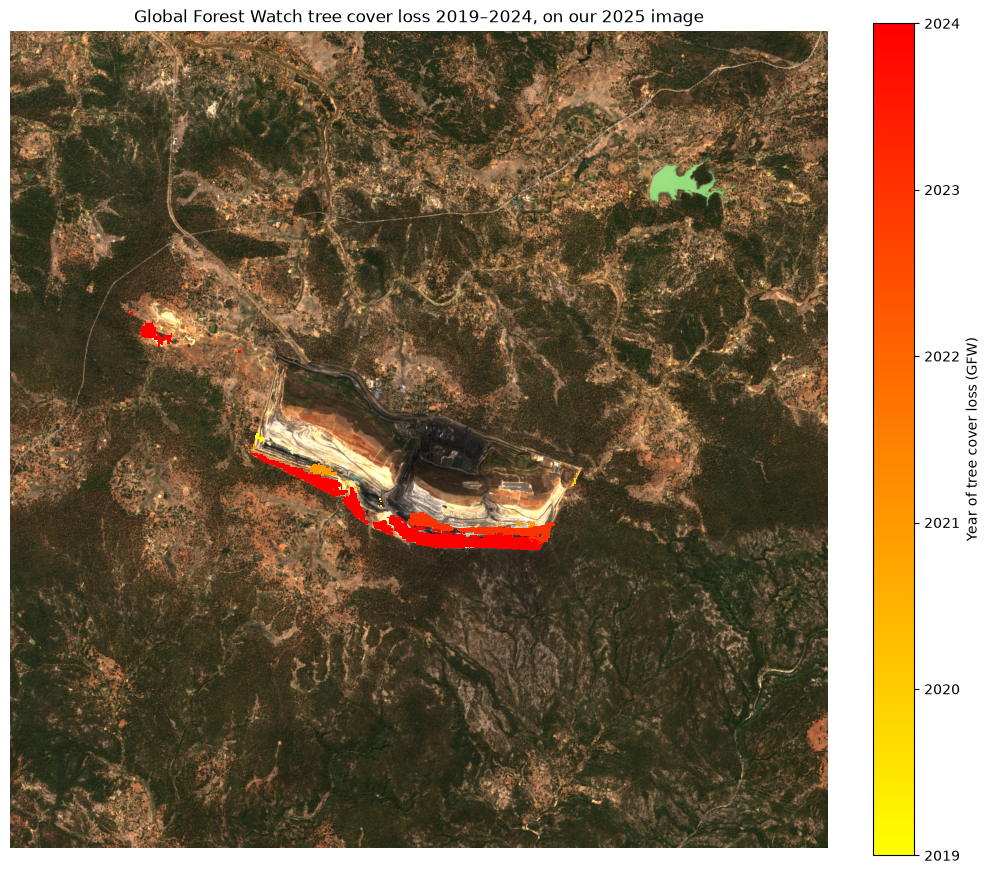

In [5]:
loss_years = np.ma.masked_where((gfw_year < 19) | (gfw_year > 24), gfw_year.astype(int) + 2000)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(image_2025)
shown = ax.imshow(loss_years, cmap="autumn_r", vmin=2019, vmax=2024, interpolation="nearest")
plt.colorbar(shown, ax=ax, fraction=0.046, label="Year of tree cover loss (GFW)")
ax.set_title("Global Forest Watch tree cover loss 2019–2024, on our 2025 image")
ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "gfw_loss_map.png", dpi=120)
plt.show()

Almost all of it is around the mine: the southern edge of the pit and the north-west clearing, exactly where the images changed.

## Step 4 – Turn GFW's pixels into patch answers

GFW answers per 30 m pixel; our model answers per 640 m patch. To compare, we ask for each patch: **what fraction of it did GFW mark as lost in 2019–2024?**

Then we need a rule for when a patch counts as "GFW says forest was lost here". We use **≥ 10% of the patch**. That's a choice, not a law of nature, so Step 6 checks how much the answer depends on it.

Patches with any GFW loss:          26
Patches with ≥10% of area lost:     11   <- our 'ground truth'


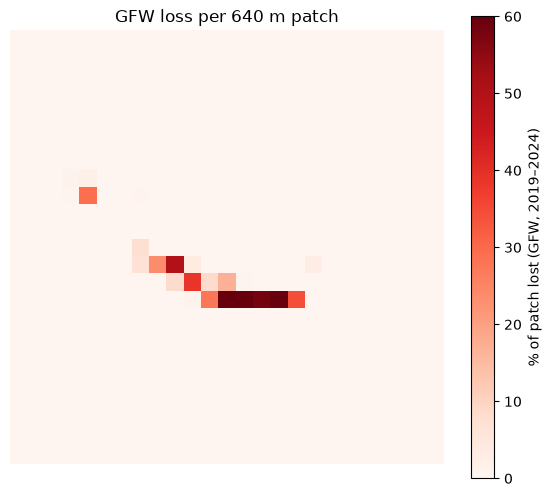

In [6]:
lost_pixels = (gfw_year >= 19) & (gfw_year <= 24)
gfw_fraction = lost_pixels.reshape(N_PATCHES, PATCH, N_PATCHES, PATCH).mean(axis=(1, 3))   # one number per patch

GFW_THRESHOLD = 0.10
gfw_loss = gfw_fraction >= GFW_THRESHOLD

print(f"Patches with any GFW loss:          {(gfw_fraction > 0).sum()}")
print(f"Patches with ≥{GFW_THRESHOLD:.0%} of area lost:     {gfw_loss.sum()}   <- our 'ground truth'")

fig, ax = plt.subplots(figsize=(7, 6))
shown = ax.imshow(gfw_fraction * 100, cmap="Reds", vmin=0, vmax=60)
plt.colorbar(shown, label="% of patch lost (GFW, 2019–2024)")
ax.set_title("GFW loss per 640 m patch")
ax.axis("off")
plt.show()

## Step 5 – Score our detections

Every patch falls into one of four boxes:

| | GFW says **lost** | GFW says **not lost** |
|---|---|---|
| **We said lost** | ✅ **True positive (TP)**: we both agree | ❌ **False positive (FP)**: a false alarm |
| **We said not lost** | ❌ **False negative (FN)**: we missed it | ✅ **True negative (TN)**: we both say nothing happened |

Then the same scores you met in notebook 03, now for *deforestation*:
- **Precision** = TP ÷ (TP + FP) → *when we raise an alarm, how often is it real?*
- **Recall** = TP ÷ (TP + FN) → *of the real losses, how many did we catch?*
- **F1** = one number combining both

Ignoring the TN box is deliberate: most patches had no loss, so "accuracy" would look great even for a model that never detects anything.

In [7]:
def score(detected, truth):
    tp = (detected & truth).sum()
    fp = (detected & ~truth).sum()
    fn = (~detected & truth).sum()
    tn = (~detected & ~truth).sum()
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, precision=precision, recall=recall, f1=f1)

simple = score(our_loss, gfw_loss)
print(f"                    GFW lost   GFW not lost")
print(f"We said lost        TP = {simple['TP']:3d}   FP = {simple['FP']:3d}")
print(f"We said not lost    FN = {simple['FN']:3d}   TN = {simple['TN']:3d}")
print()
print(f"Precision: {simple['precision']:.0%}   (of our alarms, how many were real)")
print(f"Recall:    {simple['recall']:.0%}   (of real losses, how many we caught)")
print(f"F1:        {simple['f1']:.0%}")

                    GFW lost   GFW not lost
We said lost        TP =   9   FP =  10
We said not lost    FN =   2   TN = 604

Precision: 47%   (of our alarms, how many were real)
Recall:    82%   (of real losses, how many we caught)
F1:        60%


### The agreement map

- **Green** = we both found loss (TP)
- **Red** = our false alarms (FP)
- **Yellow** = loss we missed (FN)

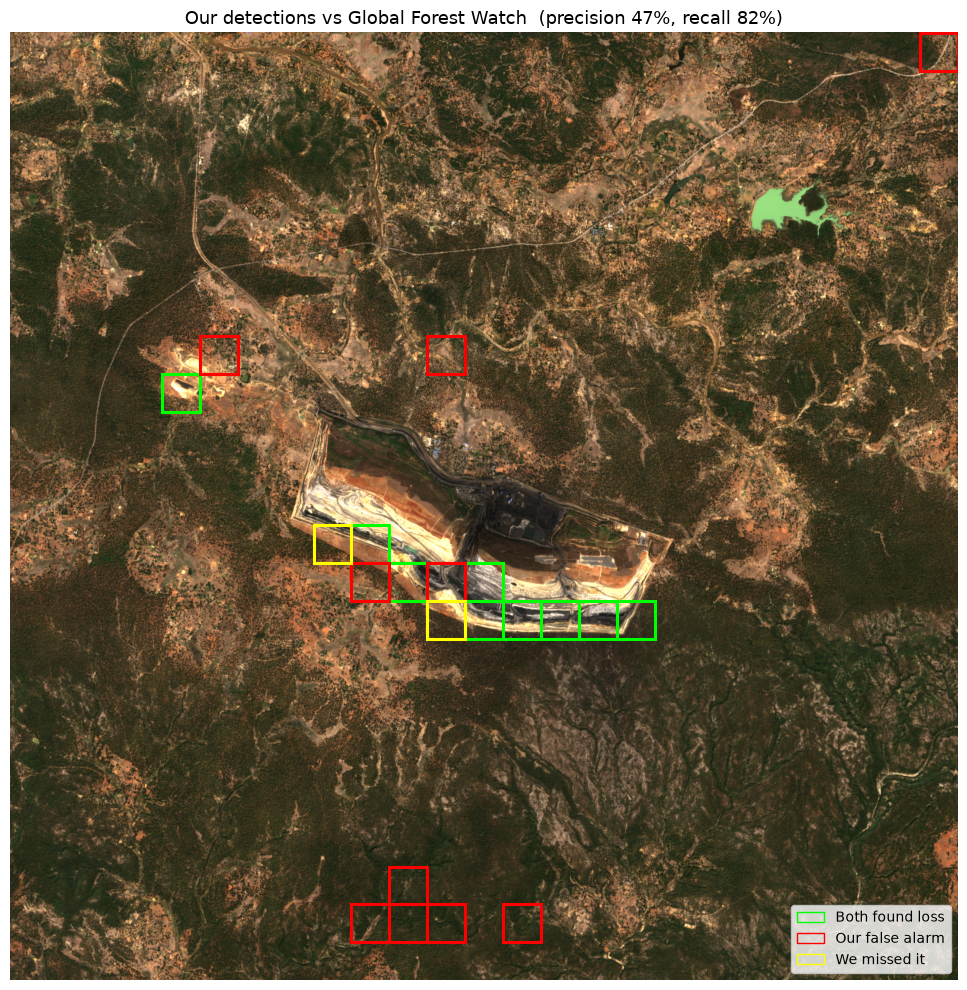

In [8]:
def draw(ax, mask, colour, lw=2.2):
    for r, c in zip(*np.nonzero(mask)):
        ax.add_patch(Rectangle((c * PATCH, r * PATCH), PATCH, PATCH, fill=False, edgecolor=colour, lw=lw))

def agreement_map(ax, detected, title):
    ax.imshow(image_2025)
    draw(ax, detected & gfw_loss, "lime")
    draw(ax, detected & ~gfw_loss, "red")
    draw(ax, ~detected & gfw_loss, "yellow")
    ax.set_title(title, fontsize=13)
    ax.axis("off")
    ax.legend(handles=[Patch(edgecolor=c, fill=False, label=l) for c, l in
                       [("lime", "Both found loss"), ("red", "Our false alarm"), ("yellow", "We missed it")]],
              loc="lower right", fontsize=10)

fig, ax = plt.subplots(figsize=(10, 10))
agreement_map(ax, our_loss, f"Our detections vs Global Forest Watch  (precision {simple['precision']:.0%}, recall {simple['recall']:.0%})")
plt.tight_layout()
plt.savefig(FIG_DIR / "validation_map_simple.png", dpi=120)
plt.show()

**Reading it:** the green boxes hug the mine, which is where real clearing happened. The red boxes at the far south are the hill-shadow false alarms you spotted in notebook 04. Check the others yourself: are they real change GFW didn't count, or model mistakes?

One thing to keep in mind: **GFW isn't perfect either.** It's a model too, just a very well-tested one. When we disagree, it's not automatically our mistake. For example, GFW only counts loss of *trees*; if the mine expanded onto scrub or fields, GFW wouldn't flag it but our "forest → not forest" might.

## Step 6 – Does the 10% rule matter?

We picked "≥ 10% of the patch lost" as the meaning of a GFW loss patch. Let's see how the scores change if we'd picked differently.

In [9]:
print(f"{'GFW rule':12} {'GFW patches':>12} {'TP':>4} {'FP':>4} {'FN':>4} {'precision':>10} {'recall':>7}")
for t in (0.01, 0.05, 0.10, 0.25, 0.50):
    s = score(our_loss, gfw_fraction >= t)
    print(f"≥ {t:4.0%} lost  {(gfw_fraction >= t).sum():12d} {s['TP']:4d} {s['FP']:4d} {s['FN']:4d} {s['precision']:10.0%} {s['recall']:7.0%}")

GFW rule      GFW patches   TP   FP   FN  precision  recall
≥   1% lost            20   11    8    9        58%     55%
≥   5% lost            15   11    8    4        58%     73%
≥  10% lost            11    9   10    2        47%     82%
≥  25% lost             9    8   11    1        42%     89%
≥  50% lost             4    4   15    0        21%    100%


The pattern: with a strict rule (only heavily cleared patches count), we catch nearly all of them (high recall) but more of our alarms look "false". With a loose rule, the reverse. The conclusion that **we catch most of the big clearings** holds whichever rule you pick. Reporting this table in the paper shows the result isn't a lucky choice of threshold.

## Step 7 – A better detection method?

Our simple method only looks at the **label**: Forest → not Forest. But the model gives more than a label: a **probability of Forest** for each patch. A patch going from 99% forest to 55% forest is a big change, even though the label stays "Forest". And a patch going from 51% to 49% flips the label over almost nothing.

**New method:** flag a patch if its **Forest probability dropped by a lot** between 2019 and 2025:

`drop = forest_prob_2019 − forest_prob_2025`

First, does the drop actually relate to GFW's loss? Each dot below is one patch.

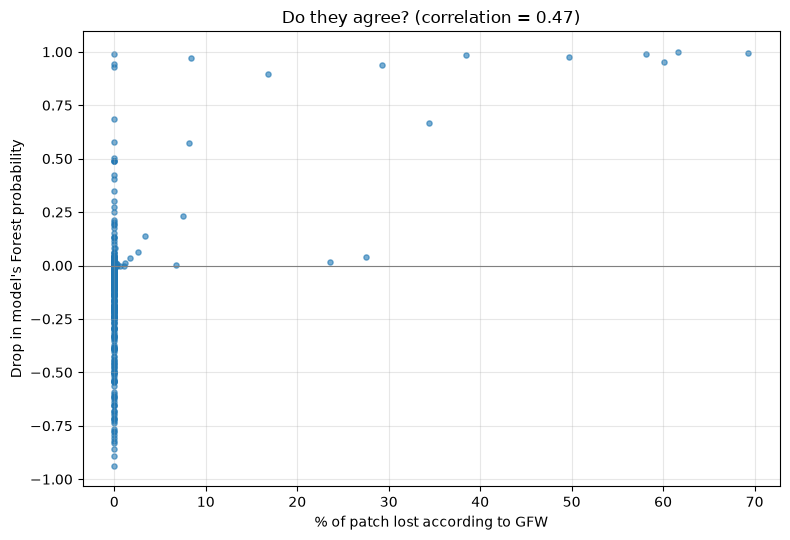

In [10]:
drop = forest_prob_2019 - forest_prob_2025

plt.figure(figsize=(8, 5.5))
plt.scatter(gfw_fraction.ravel() * 100, drop.ravel(), s=14, alpha=0.6)
plt.axhline(0, color="gray", lw=0.8)
plt.xlabel("% of patch lost according to GFW")
plt.ylabel("Drop in model's Forest probability")
plt.title(f"Do they agree? (correlation = {np.corrcoef(drop.ravel(), gfw_fraction.ravel())[0, 1]:.2f})")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "probability_drop_vs_gfw.png", dpi=150)
plt.show()

The patches GFW says lost a lot of forest (right side) mostly have big drops. The patches with no loss (the big pile at 0%) are spread up and down. That spread is the noise.

**Correlation** is a number from −1 to +1 measuring how well two things move together: 0 = no relationship, 1 = perfect. Around 0.5 is a moderate relationship.

### Choosing how big a drop counts

Try different cut-offs for the drop and score each one. The **★** marks our simple label method from Step 5 for comparison.

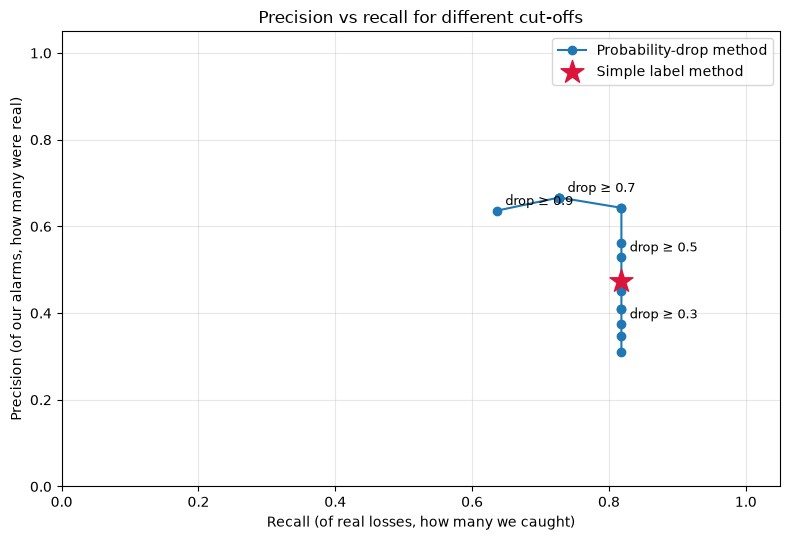

 cut-off  alarms  precision  recall    F1
    0.20      29        31%     82%   45%
    0.25      26        35%     82%   49%
    0.30      24        38%     82%   51%
    0.35      22        41%     82%   55%
    0.40      22        41%     82%   55%
    0.45      20        45%     82%   58%
    0.50      17        53%     82%   64%
    0.55      16        56%     82%   67%
    0.60      14        64%     82%   72%
    0.65      14        64%     82%   72%
    0.70      12        67%     73%   70%
    0.75      12        67%     73%   70%
    0.80      12        67%     73%   70%
    0.85      12        67%     73%   70%
    0.90      11        64%     64%   64%


In [11]:
cutoffs = np.round(np.arange(0.2, 0.95, 0.05), 2)
curve = [score(drop >= t, gfw_loss) for t in cutoffs]

plt.figure(figsize=(8, 5.5))
plt.plot([s["recall"] for s in curve], [s["precision"] for s in curve], "o-", label="Probability-drop method")
for t, s in zip(cutoffs, curve):
    if t in (0.3, 0.5, 0.7, 0.9):
        plt.annotate(f"drop ≥ {t}", (s["recall"], s["precision"]), textcoords="offset points", xytext=(6, 4), fontsize=9)
plt.scatter(simple["recall"], simple["precision"], marker="*", s=300, color="crimson", zorder=3, label="Simple label method")
plt.xlabel("Recall (of real losses, how many we caught)")
plt.ylabel("Precision (of our alarms, how many were real)")
plt.xlim(0, 1.05); plt.ylim(0, 1.05)
plt.title("Precision vs recall for different cut-offs")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "precision_recall_methods.png", dpi=150)
plt.show()

print(f"{'cut-off':>8} {'alarms':>7} {'precision':>10} {'recall':>7} {'F1':>5}")
for t, s in zip(cutoffs, curve):
    print(f"{t:8.2f} {s['TP'] + s['FP']:7d} {s['precision']:10.0%} {s['recall']:7.0%} {s['f1']:5.0%}")

**This is a trade-off curve.** Moving right (lower cut-off) catches more real loss but raises more false alarms; moving up (higher cut-off) means fewer, more reliable alarms. Points **above and to the right** of the ★ beat the simple method on both scores.

⚠️ **An important catch (put this in your paper):** we chose the cut-off by *looking at GFW's answers*. That's like picking your exam strategy after seeing the answer key, so the best cut-off here will look better than it really is. To prove it truly works you'd fix the cut-off now, then test it on a **different area** (for example, another mine in Hasdeo, or a region in Northeast India). That's a great next step.

Let's use **drop ≥ 0.5** (a round, middle-of-the-road choice) and compare the two methods side by side.

Method                            alarms   TP   FP   FN  precision  recall    F1
Simple: Forest -> not Forest          19    9   10    2        47%     82%   60%
Probability drop ≥ 0.5                17    9    8    2        53%     82%   64%


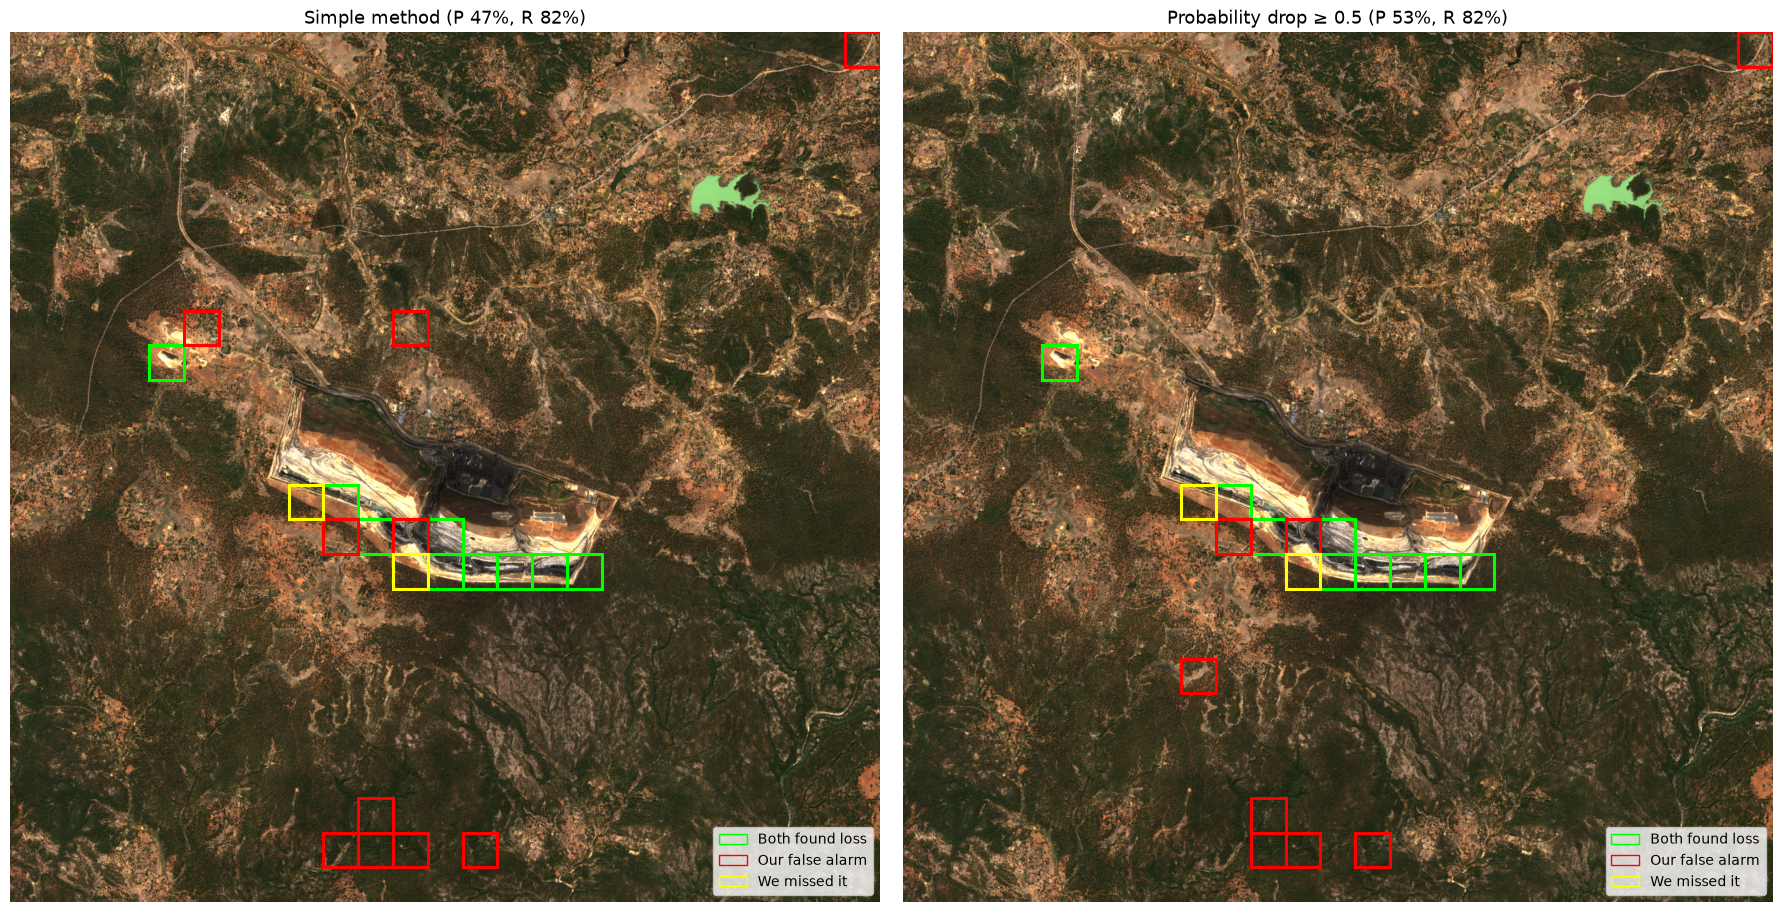

In [12]:
DROP_CUTOFF = 0.5
better = score(drop >= DROP_CUTOFF, gfw_loss)

print(f"{'Method':32} {'alarms':>7} {'TP':>4} {'FP':>4} {'FN':>4} {'precision':>10} {'recall':>7} {'F1':>5}")
for name, s in [("Simple: Forest -> not Forest", simple), (f"Probability drop ≥ {DROP_CUTOFF}", better)]:
    print(f"{name:32} {s['TP'] + s['FP']:7d} {s['TP']:4d} {s['FP']:4d} {s['FN']:4d} {s['precision']:10.0%} {s['recall']:7.0%} {s['f1']:5.0%}")

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
agreement_map(axes[0], our_loss, f"Simple method (P {simple['precision']:.0%}, R {simple['recall']:.0%})")
agreement_map(axes[1], drop >= DROP_CUTOFF, f"Probability drop ≥ {DROP_CUTOFF} (P {better['precision']:.0%}, R {better['recall']:.0%})")
plt.tight_layout()
plt.savefig(FIG_DIR / "validation_map_comparison.png", dpi=110)
plt.show()

## Step 8 – How much area?

Finally, compare the **amount** of forest loss.
- GFW counts individual 30 m pixels, so its number is precise.
- We count whole 640 m patches (0.41 km² each), so every detection counts the *entire* patch as lost, even if only a corner was cleared. That's the **mixed-patch problem** from your answer to question 4 in notebook 04.

In [13]:
gfw_km2 = lost_pixels.sum() / 10_000
our_km2 = our_loss.sum() * PATCH_KM2
tp_km2 = (gfw_fraction[our_loss & gfw_loss]).sum() * PATCH_KM2

print(f"GFW tree cover loss 2019–2024:            {gfw_km2:5.2f} km²")
print(f"Our estimate (whole patches):             {our_km2:5.2f} km²   ({our_km2 / gfw_km2:.1f}× GFW)")
print(f"Actual GFW loss inside our correct patches: {tp_km2:4.2f} km²   ({tp_km2 / gfw_km2:.0%} of all GFW loss)")

GFW tree cover loss 2019–2024:             2.09 km²
Our estimate (whole patches):              7.78 km²   (3.7× GFW)
Actual GFW loss inside our correct patches: 1.71 km²   (82% of all GFW loss)


So our patches *point to the right places* and contain most of the real loss, but counting whole patches **overestimates the area** several times over. For measuring "how many km² were cleared", 640 m patches are too coarse. For flagging "where is clearing happening", they work.

## Step 9 – Summary for your paper

In [14]:
print("=== Validation against Global Forest Watch (Hansen GFC v1.13) ===")
print(f"Study area:           16 × 16 km around PEKB mine, Hasdeo Arand (625 patches of 640 m)")
print(f"Dates:                {RESULTS['scenes'][0]}  vs  {RESULTS['scenes'][1]}")
print(f"GFW loss 2019–2024:   {gfw_km2:.2f} km², in {gfw_loss.sum()} patches (≥{GFW_THRESHOLD:.0%} of patch)")
print()
for name, s in [("Simple label method", simple), (f"Probability drop ≥ {DROP_CUTOFF}", better)]:
    print(f"{name:26} precision {s['precision']:.0%}, recall {s['recall']:.0%}, F1 {s['f1']:.0%}  "
          f"(TP {s['TP']}, FP {s['FP']}, FN {s['FN']})")
print()
print(f"Area: we estimate {our_km2:.1f} km² vs GFW {gfw_km2:.2f} km² ({our_km2 / gfw_km2:.1f}× overestimate)")
print()
print("Figures:", [f.name for f in sorted(FIG_DIR.glob("*.png")) if f.stem.startswith(("gfw", "validation", "probability", "precision"))])

=== Validation against Global Forest Watch (Hansen GFC v1.13) ===
Study area:           16 × 16 km around PEKB mine, Hasdeo Arand (625 patches of 640 m)
Dates:                S2A_44QPL_20190220_0_L2A  vs  S2C_44QPL_20250208_0_L2A
GFW loss 2019–2024:   2.09 km², in 11 patches (≥10% of patch)

Simple label method        precision 47%, recall 82%, F1 60%  (TP 9, FP 10, FN 2)
Probability drop ≥ 0.5     precision 53%, recall 82%, F1 64%  (TP 9, FP 8, FN 2)

Area: we estimate 7.8 km² vs GFW 2.09 km² (3.7× overestimate)

Figures: ['gfw_loss_map.png', 'gfw_loss_per_year.png', 'precision_recall_methods.png', 'probability_drop_vs_gfw.png', 'validation_map_comparison.png', 'validation_map_simple.png']


## Done – you have the core result of your paper

**Your findings, in plain words:**
1. A model trained only on European images, applied to an Indian forest, **found most of the forest loss** that Global Forest Watch independently recorded around the Hasdeo coal mine.
2. But **many of its alarms were false**: hill shadows, and noise from mixed patches, so precision was moderate.
3. Using the **probability** of Forest instead of just the label gave a modest improvement, but this needs testing on another area to be sure.
4. 640 m patches **overestimate the area** cleared, so they're good for *finding* clearing, poor for *measuring* it.

That's a complete, honest research story: method, result, validation, limitations, next steps.

**What comes next:** writing the paper. We can go section by section (Abstract, Introduction, Methods, Results, Discussion), using your figures and these numbers.

## Think about it (answer in chat)

1. Our recall is high but precision is moderate. For a deforestation **alert system** (e.g. sending rangers to check), which would you rather have high, and why?
2. Pick one red box (false alarm) on the agreement map. Is it really our mistake, or could GFW have missed something?
3. Why is it a problem that we chose the 0.5 cut-off while looking at GFW's answers?
4. GFW's 2025 bar is the biggest, but our model couldn't see it. What would you change in the study to capture it?